# 09 — Executive summary

**Read time: ~2 minutes.** This notebook is the elevator pitch for the project: the question we asked, the answer we got, the recommendation it implies under the supplied economics, and where to dig in next. All charts and numbers are produced by the same `uplift_marketing` package documented in the deeper notebooks (NB01–NB07).


## The question

> *Which customers will respond to the campaign **because** of the campaign — and what is the profit-optimal contact budget?*

Naive response-rate models answer the wrong question — they rank customers by likelihood of converting, including those who would have converted anyway. **Uplift modelling** ranks customers by the *causal* effect of being contacted, which is the right ranking when contact is costly.


## What we did

1. Loaded the Hillstrom MineThatData campaign dataset (64,000 customers, randomized email vs no-email).
2. Trained a calibrated T-learner uplift model with isotonic-regression calibration to close the predicted-vs-realised gap on this rare-event data (≈1% conversion rate).
3. Evaluated with AUUC, normalized Qini, and bootstrap CIs on policy value (NB05).
4. Found the profit-optimal contact fraction at the supplied economics, plus a sensitivity sweep across plausible cost / value scenarios (NB06).
5. Wrote a stakeholder-facing model card and policy report covering causal assumptions, randomization diagnostics, and misuse risks.


In [1]:
import sys
from pathlib import Path

_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(_ROOT / "src"))

import json
import pandas as pd
from IPython.display import Image, Markdown

from uplift_marketing.notebook_utils import setup_notebook

config = setup_notebook()
DASHBOARD_DIR = config.reports_dir / "dashboard"
FIGURES_DIR = DASHBOARD_DIR / "figures"

if not (DASHBOARD_DIR / "model_summary.json").exists():
    raise RuntimeError(
        "Run NB06 first to populate reports/dashboard/ — this notebook "
        "reads the artifacts produced by export_dashboard."
    )
summary = json.loads((DASHBOARD_DIR / "model_summary.json").read_text())
rec = summary["recommendation"]
econ = summary["economics"]

## The headline result

Under the placeholder economics (cost per contact and value per conversion are dataset defaults — replace with the campaign owner's numbers before any production use):

In [2]:
Markdown(
    f"- Recommended target: **top {rec['fraction']:.2%}** of customers "
    f"by predicted uplift ({rec['n_selected']:,} customers).\n"
    f"- Cut-off uplift score: `{rec['threshold_score']:+.4f}`.\n"
    f"- Predicted incremental conversions: "
    f"**{rec['predicted_incremental_conversions']:.0f}**.\n"
    f"- Predicted net profit: **{econ['currency']} "
    f"{rec['predicted_net_profit']:,.0f}** at break-even uplift "
    f"`{econ['break_even_uplift']:.4f}`.\n"
    f"- Naive ATE on the evaluation split: "
    f"`{summary['naive_ate']:+.4f}` · normalized Qini: "
    f"`{summary['normalized_qini']['normalized']:+.4f}`.\n"
)

- Recommended target: **top 8.00%** of customers by predicted uplift (1,536 customers).
- Cut-off uplift score: `+0.0098`.
- Predicted incremental conversions: **26**.
- Predicted net profit: **EUR 205** at break-even uplift `0.0100`.
- Naive ATE on the evaluation split: `+0.0049` · normalized Qini: `-0.0112`.


### One chart, one decision

Predicted profit as a function of the contact budget, with the profit-optimal cut-off marked. The curve typically rises early (high-uplift customers pay for their contact), peaks, then falls past break-even as additional contacts cost more than they earn.

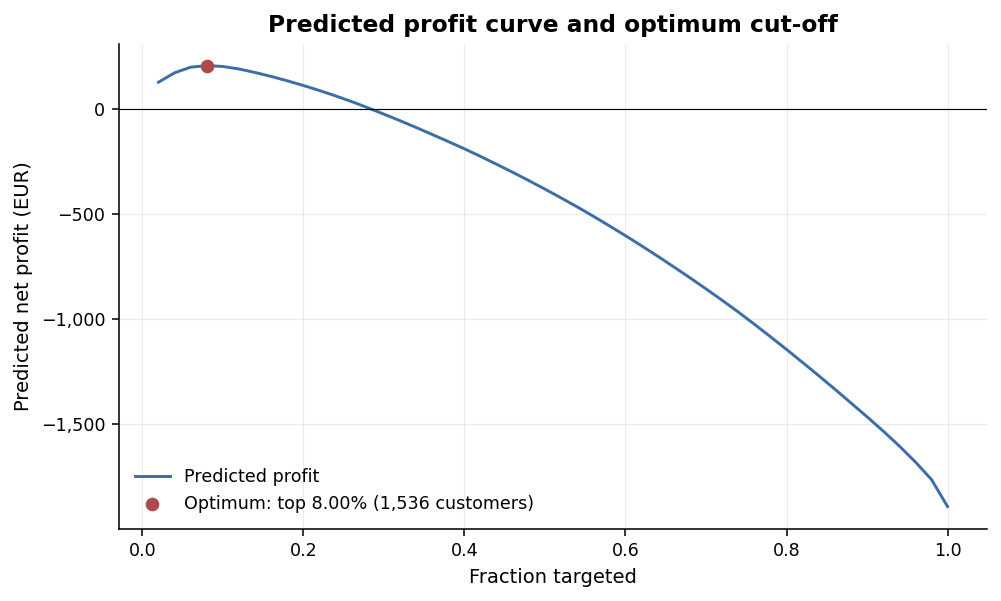

In [3]:
Image(filename=str(FIGURES_DIR / "campaign_profit.png"))

### Sensitivity to economics

The recommendation is contingent on the supplied cost / value numbers. The chart below sweeps plausible scenarios. **If the policy ranking flips between two scenarios, escalate to the campaign owner before shipping.**

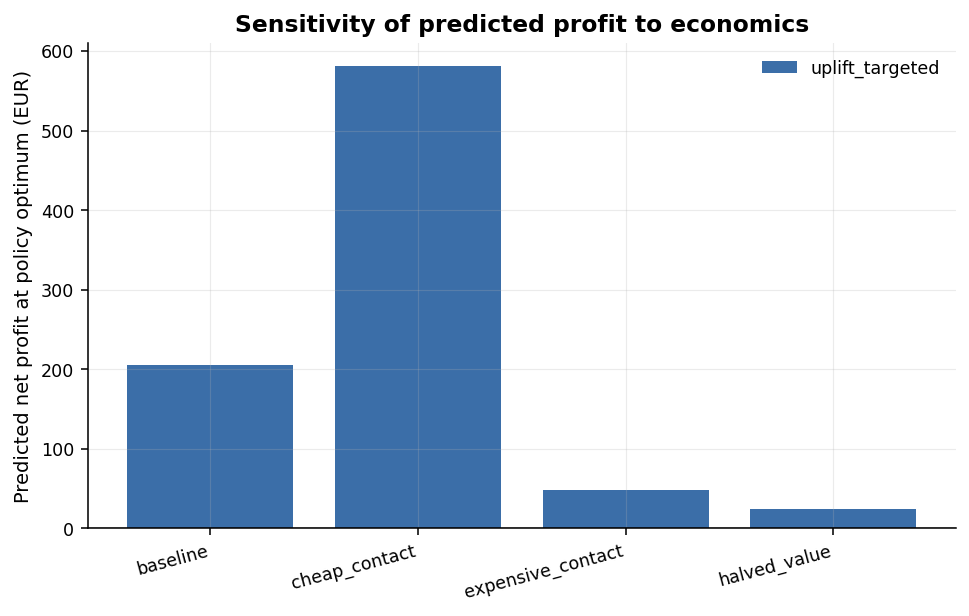

In [4]:
Image(filename=str(FIGURES_DIR / "campaign_scenarios.png"))

## What we cannot say

Every number above is contingent on the causal assumptions documented in [`reports/dashboard/model_card.md`](../reports/dashboard/model_card.md):

- **Random treatment assignment** — verified for this dataset   (sample-ratio mismatch and per-feature SMD checks pass).
- **SUTVA / no interference** — *unverifiable*. Plausible for   arm's-length email, dubious for B2B / shared-inbox / social-  graph scenarios.
- **Consistency** — *unverifiable*. A different creative or   channel is out-of-distribution for this model; re-validate.
- **Positivity** — holds under random assignment by   construction. If real-world contact eligibility is   conditional, restrict scoring to the eligible subpopulation.

The model card also lists named misuse risks — proxy targeting, self-fulfilling prophecies, OOD reuse, treating point estimates as ground truth, and score leakage into other systems. **A deployment reviewer should sign off the model card before this recommendation goes live.**


## Where to look next

| Question | Notebook |
| --- | --- |
| Why uplift, not response rate? | [NB01](01_problem_framing_incrementality_not_conversion.ipynb) |
| Is the experiment clean? | [NB02](02_data_exploration_treatment_control_outcomes.ipynb) |
| What's wrong with response models? | [NB03](03_baseline_response_model_and_why_it_fails.ipynb) |
| S/T/X-learner comparison | [NB04](04_uplift_models_s_learner_t_learner_x_learner.ipynb) |
| AUUC, Qini, policy CIs | [NB05](05_qini_gain_and_policy_evaluation.ipynb) |
| Budget optimisation, scenarios, dashboard exports | [NB06](06_budget_allocation_and_campaign_simulation.ipynb) |
| Causal-assumption stress tests, fairness panels | [NB07](07_bias_limitations_and_causal_assumptions.ipynb) |
| Black-box uplift comparison | [NB08](08_comparison_with_black_box_uplift_models.ipynb) |

**Hand-off artifacts** (regenerated by `export_dashboard`):

- [`reports/dashboard/policy_report.md`](../reports/dashboard/policy_report.md) — full report.
- [`reports/dashboard/model_card.md`](../reports/dashboard/model_card.md) — causal assumptions and misuse risks.
- [`reports/dashboard/recommended_targets.csv`](../reports/dashboard/recommended_targets.csv) — every customer flagged at the cut-off.
- [`reports/dashboard/budget_scenarios.csv`](../reports/dashboard/budget_scenarios.csv) — sensitivity sweep.
